In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.collections import PolyCollection
from PIL import Image
from matplotlib.transforms import Affine2D
from scipy.ndimage import gaussian_filter, label

measured_tiff_path = Path(
    '/Users/yiyangzhi/Library/CloudStorage/'
    'GoogleDrive-yiyang_zhi3@berkeley.edu/Other computers/'
    'USB and External Devices/KINGSTON/trouble_shoot_focus/'
    'ZD1_(1_1)_Ca1_RMQA.tif'
)

In [2]:
# Change these values, then rerun this cell and the plotting cells below.
FONT_FAMILY = "Arial"  # Choose an installed font, e.g. "Arial" or "Times New Roman".
FONT_SIZE = 16  # points

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "savefig.dpi": 600,  # High resolution for exported images.
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE,
    "legend.title_fontsize": FONT_SIZE,
    "figure.titlesize": FONT_SIZE,
})

In [3]:
stl_path = Path(
    '/Users/yiyangzhi/Library/CloudStorage/'
    'GoogleDrive-yiyang_zhi3@berkeley.edu/My Drive/'
    'Ming Wu Integrated Photonics Group/Simulations/Fusion_360_Model/'
    'Integrated_Trapped_Ions_Library/FINAL/'
    'Ca_IPS_BFL153p2_f106um_FINAL_lens.STP.stl'
)

elev_deg = 0
azim_deg = 90

155,052 triangles; 77,528 unique vertices
Coordinates are in STL units; the STL format does not specify units.
X: -42.0004 to 42.0004 (span 84.0008)
Y: -5.00005 to 5.00005 (span 10.0001)
Z: 5.00007 to 25 (span 19.9999)


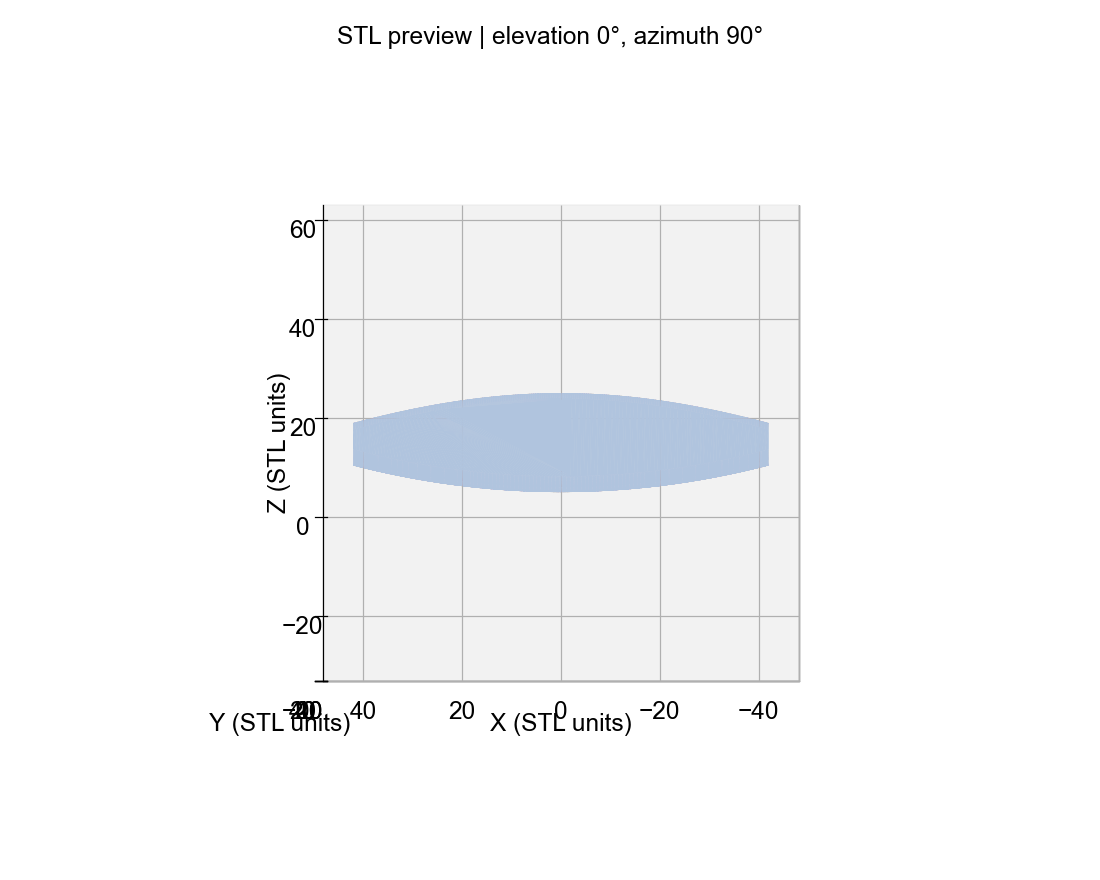

In [4]:
# Read this binary STL directly; no additional mesh package is needed.
triangle_dtype = np.dtype([
    ('normal', '<f4', (3,)),
    ('vertices', '<f4', (3, 3)),
    ('attribute', '<u2'),
])
with stl_path.open('rb') as stream:
    header = stream.read(80)
    count_bytes = stream.read(4)
    if len(count_bytes) != 4:
        raise ValueError('The STL header is incomplete.')
    triangle_count = int.from_bytes(count_bytes, byteorder='little')
    if stl_path.stat().st_size != 84 + 50 * triangle_count:
        raise ValueError('Expected a complete binary STL file.')
    records = np.fromfile(stream, dtype=triangle_dtype, count=triangle_count)

triangles = records['vertices'].astype(np.float64)
vertices = np.unique(triangles.reshape(-1, 3), axis=0)
bounds = np.array([vertices.min(axis=0), vertices.max(axis=0)])
extent = bounds[1] - bounds[0]
center = bounds.mean(axis=0)
print(f'{triangle_count:,} triangles; {len(vertices):,} unique vertices')
print('Coordinates are in STL units; the STL format does not specify units.')
for axis, low, high, span in zip('XYZ', bounds[0], bounds[1], extent):
    print(f'{axis}: {low:.6g} to {high:.6g} (span {span:.6g})')

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.add_collection3d(Poly3DCollection(
    triangles, facecolor='lightsteelblue', edgecolor='none',
    linewidth=0, rasterized=True,
))
# Equal axis scales preserve the geometry; orthographic view avoids perspective distortion.
half_span = max(extent.max() * 0.55, 1e-9)
ax.set_xlim(center[0] - half_span, center[0] + half_span)
ax.set_ylim(center[1] - half_span, center[1] + half_span)
ax.set_zlim(center[2] - half_span, center[2] + half_span)
ax.set_box_aspect((1, 1, 1))
ax.set_proj_type('ortho')
ax.view_init(elev=elev_deg, azim=azim_deg)
ax.set(xlabel='X (STL units)', ylabel='Y (STL units)', zlabel='Z (STL units)')
ax.set_title(f'STL preview | elevation {elev_deg}°, azimuth {azim_deg}°')
plt.tight_layout()
plt.show()

In [5]:
# X–Z silhouette from either side of Y, matching the 3D preview settings.


view_azimuth_deg = (float(azim_deg) + 180.0) % 360.0 - 180.0
if (not np.isfinite(float(elev_deg)) or not np.isfinite(view_azimuth_deg)
        or not np.isclose(float(elev_deg), 0.0, rtol=0, atol=1e-8)
        or not np.isclose(abs(view_azimuth_deg), 90.0, rtol=0, atol=1e-8)):
    raise ValueError('For an X–Z view, set elev_deg = 0 and azim_deg = -90 or +90.')
camera_y_sign = 1.0 if view_azimuth_deg > 0 else -1.0
view_direction_xyz = np.array([0.0, -camera_y_sign, 0.0])  # Camera toward object.
view_side_label = 'from +Y toward −Y' if camera_y_sign > 0 else 'from −Y toward +Y'

mesh_vertices_um, vertex_ids = np.unique(
    triangles.reshape(-1, 3), axis=0, return_inverse=True
)
face_ids = vertex_ids.reshape(-1, 3)
mesh_edges = np.concatenate([
    face_ids[:, [0, 1]], face_ids[:, [1, 2]], face_ids[:, [2, 0]],
])
mesh_edges.sort(axis=1)
unique_edges, edge_ids, edge_counts = np.unique(
    mesh_edges, axis=0, return_inverse=True, return_counts=True
)
face_normals = np.cross(
    triangles[:, 1] - triangles[:, 0], triangles[:, 2] - triangles[:, 0]
)
normal_along_view = face_normals @ view_direction_xyz
edge_face_signs = np.tile(np.sign(normal_along_view), 3)
min_sign = np.full(len(unique_edges), np.inf)
max_sign = np.full(len(unique_edges), -np.inf)
np.minimum.at(min_sign, edge_ids, edge_face_signs)
np.maximum.at(max_sign, edge_ids, edge_face_signs)
silhouette_mask = (min_sign < max_sign) | (edge_counts != 2)
silhouette_segments_um = mesh_vertices_um[unique_edges[silhouette_mask]]
if not len(silhouette_segments_um):
    raise ValueError('No silhouette edges found; check the mesh orientation.')

# Intersect candidate segments with vertical lines in the X–Z projection.
# Taking the outermost Z values removes internal/hidden silhouette candidates.
# Include every candidate endpoint X as well as a uniform sampling grid.
# The returned points are interpolated on mesh edges, not fitted curves.
x_samples_um = np.unique(np.concatenate([
    np.linspace(bounds[0, 0], bounds[1, 0], 2001),
    silhouette_segments_um[:, :, 0].ravel(),
]))
segment_start = silhouette_segments_um[:, 0][:, [0, 2]]
segment_end = silhouette_segments_um[:, 1][:, [0, 2]]
delta = segment_end - segment_start
x_tolerance_um = max(float(np.ptp(mesh_vertices_um[:, 0])), 1.0) * 1e-10
vertical = np.abs(delta[:, 0]) <= x_tolerance_um
x_low = np.minimum(segment_start[:, 0], segment_end[:, 0])
x_high = np.maximum(segment_start[:, 0], segment_end[:, 0])
top_z_um = np.full(x_samples_um.shape, np.nan)
bottom_z_um = np.full(x_samples_um.shape, np.nan)
for i, x_um in enumerate(x_samples_um):
    active = (~vertical) & (x_um >= x_low) & (x_um <= x_high)
    fraction = (x_um - segment_start[active, 0]) / delta[active, 0]
    z_hits = segment_start[active, 1] + fraction * delta[active, 1]
    # At vertical segments, include both endpoints to retain the extreme Z.
    at_vertical = vertical & (np.abs(x_um - segment_start[:, 0]) <= x_tolerance_um)
    z_hits = np.concatenate([
        z_hits, segment_start[at_vertical, 1], segment_end[at_vertical, 1],
    ])
    if z_hits.size:
        top_z_um[i] = z_hits.max()
        bottom_z_um[i] = z_hits.min()

# Each row is [X, Z] in µm. These are projected outline points; Y is collapsed.
top_edge_xz_um = np.column_stack([x_samples_um, top_z_um])
bottom_edge_xz_um = np.column_stack([x_samples_um, bottom_z_um])

fig_edges, ax_edges = plt.subplots(figsize=(12, 5))
ax_edges.add_collection(PolyCollection(
    triangles[:, :, [0, 2]], facecolors='lightgray', edgecolors='none',
    rasterized=True, label='Projected STL',
))
ax_edges.plot(*top_edge_xz_um.T, color='crimson', linewidth=2,
              label='Upper Z edge', zorder=3)
ax_edges.plot(*bottom_edge_xz_um.T, color='royalblue', linewidth=2,
              label='Lower Z edge', zorder=3)
# Sparse markers show sample locations without obscuring the outline.
marker_step = max(1, len(x_samples_um) // 55)
ax_edges.scatter(*top_edge_xz_um[::marker_step].T, color='crimson', s=12, zorder=4)
ax_edges.scatter(*bottom_edge_xz_um[::marker_step].T, color='royalblue', s=12, zorder=4)
ax_edges.autoscale_view()
ax_edges.margins(x=0.03, y=0.15)
ax_edges.set_aspect('equal', adjustable='box')
ax_edges.set(xlabel='X (µm)', ylabel='Z (µm)',
             title=f'X–Z outlines | {view_side_label} (azimuth {view_azimuth_deg:g}°)')
# A camera on +Y sees physical X increasing toward screen-left.
if camera_y_sign > 0:
    ax_edges.invert_xaxis()
ax_edges.grid(alpha=0.25)
ax_edges.legend(loc='upper right')
fig_edges.tight_layout()
plt.show()
print(f'Top: {np.isfinite(top_z_um).sum():,} points in top_edge_xz_um, columns [X, Z] (µm)')
print(f'Bottom: {np.isfinite(bottom_z_um).sum():,} points in bottom_edge_xz_um, columns [X, Z] (µm)')

print(f'View: {view_side_label}. Saved coordinates remain physical [X, Z] in µm.')


First theoretical surface ↔ STL bottom: X-weighted RMS = 0.00024773 µm (0.248 nm); max |difference| = 0.00057557 µm (0.576 nm).
Second theoretical surface ↔ STL top: X-weighted RMS = 0.00014950 µm (0.149 nm); max |difference| = 0.00040666 µm (0.407 nm).
Comparison spans the full extracted STL aperture, with center translations only.
Small residuals can include STL faceting and rounding of the displayed design parameters.
Results retained in theory_stl_results; residual arrays are in µm.


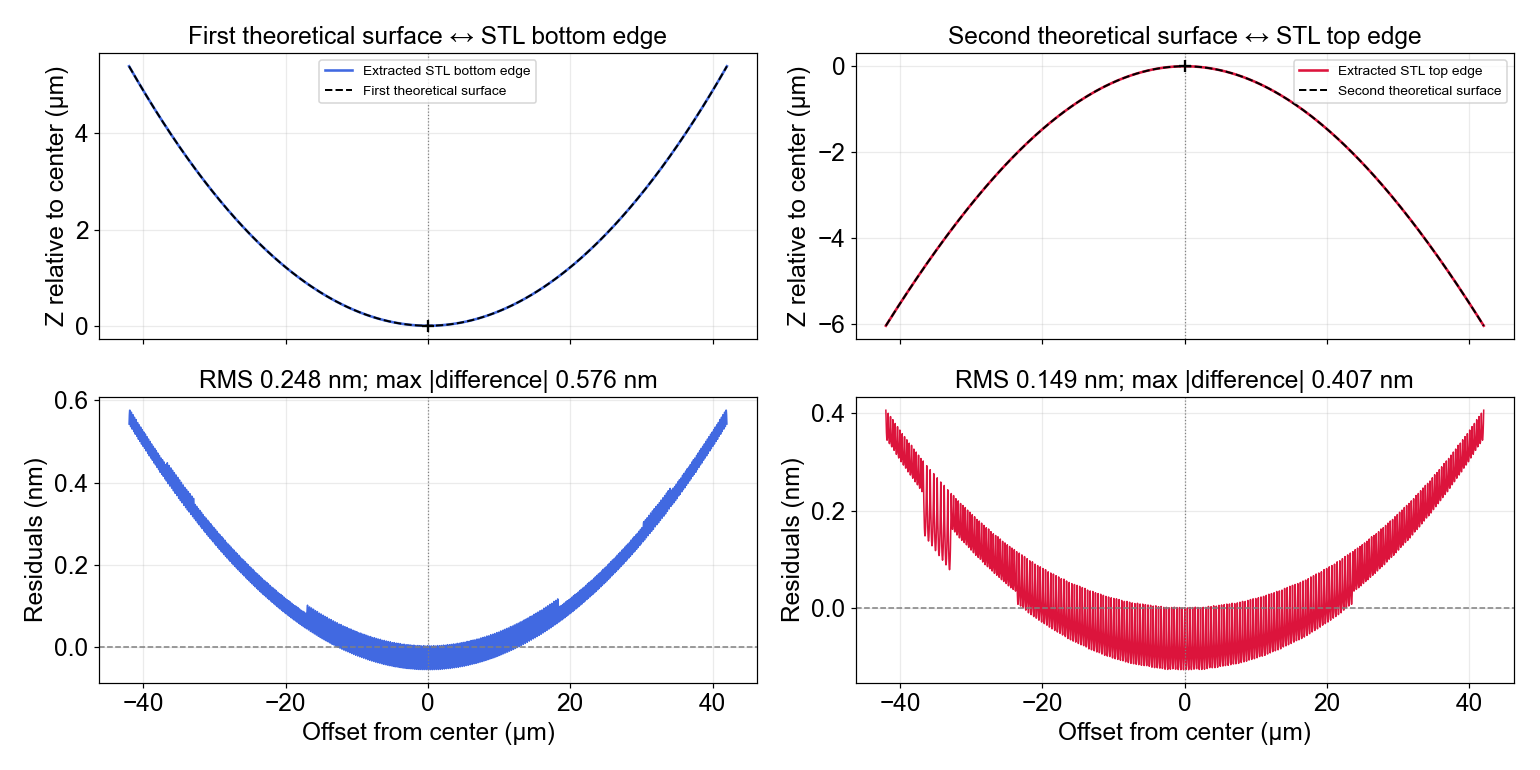

In [6]:
# Shared theoretical parameters: first surface = original TIFF right / rotated top / STL lower Z;
# second surface = original TIFF left / rotated bottom / STL upper Z.
# First Biconic Zernike row -> original right edge; second row -> original left edge.
# Compare the X meridian (optical-design y = 0), with Max Zern Terms = 0:
# z(x) = (x²/Rx) / [1 + sqrt(1 - (1+kx)x²/Rx²)] + sum(a_n*x**n)
# X is SIGNED: retain odd powers, and especially the nonzero X² coefficient.
# Reference: https://ansyshelp.ansys.com/public/Views/Secured/Zemax/v25101/en/OpticStudio_User_Guide/OpticStudio_Help/topics/Biconic_Zernike.html
# Values are transcribed at the screenshot's displayed precision.
# ASSUMPTION: optical-design length units are µm, matching the STL/calibrated TIFF.
# a_n units: µm**(1-n). The screenshot does not show the model's unit setting.
# Visible X¹...X⁷ terms are included; higher offscreen terms are assumed zero.
# Max Zern Terms = 0, so Norm Radius = 1 does not scale the X-power coefficients.

asphere_parameters = {
    'first': {
        'radius_um': 921.224,
        'conic_constant': -61.805,
        'x_coefficients': {
            1: -6.053e-10, 2: 2.494e-3, 3: -5.128e-14,
            4: 2.190e-8, 5: -9.237e-18, 6: 0.0, 7: 0.0,
        },
    },
    'second': {
        'radius_um': -103.226,
        'conic_constant': -2.822,
        'x_coefficients': {
            1: -5.568e-10, 2: 1.095e-3, 3: -3.063e-14,
            4: -7.792e-11, 5: -7.024e-18, 6: 0.0, 7: 0.0,
        },
    },
}
# Signed radii already map these surfaces into the TIFF Y ordinate:
# first has positive sag; second has negative sag. No additional sign flip or fit.


def biconic_x_sag_um(x_um, radius_um, conic_constant, x_coefficients):
    """Biconic Zernike X-section at optical y=0, with zero Zernike terms."""
    x = np.asarray(x_um, dtype=float)
    radius = float(radius_um)
    k = float(conic_constant)
    if not np.isfinite(radius) or not np.isfinite(k):
        raise ValueError('Radius and conic constant must be finite.')
    curvature = 0.0 if radius == 0 else 1.0 / radius  # OpticStudio flat convention.
    coefficients = {}
    for power, coefficient in x_coefficients.items():
        if not isinstance(power, (int, np.integer)) or not 1 <= power <= 16:
            raise ValueError('X coefficient keys must be integer powers 1...16.')
        if not np.isfinite(float(coefficient)):
            raise ValueError('X coefficients must be finite.')
        coefficients[power] = float(coefficient)
    radicand = 1 - (1 + k) * (curvature * x)**2
    valid = np.isfinite(x) & (radicand >= 0)
    sag = np.full(x.shape, np.nan)
    sag[valid] = curvature * x[valid]**2 / (1 + np.sqrt(radicand[valid]))
    for power, coefficient in coefficients.items():
        sag[valid] += coefficient * x[valid]**power
    if not np.isfinite(sag[valid]).all():
        raise ValueError('Model overflow: check coefficient units and powers.')
    return sag

def center_profile(points_um):
    points = np.asarray(points_um, dtype=float)
    points = points[np.isfinite(points).all(axis=1)]
    points = points[np.argsort(points[:, 0])]
    if len(points) < 2:
        raise ValueError('At least two finite edge points are required.')
    center_x = (points[0, 0] + points[-1, 0]) / 2
    center_height = np.interp(center_x, points[:, 0], points[:, 1])
    center_point = np.array([center_x, center_height])
    return points - center_point, center_point

theory_stl_results = {}
fig_theory_stl, axes_theory_stl = plt.subplots(2, 2, figsize=(14, 7), sharex='col')
for column, (surface_name, stl_name, edge_points, color) in enumerate([
    ('first', 'bottom', bottom_edge_xz_um, 'royalblue'),
    ('second', 'top', top_edge_xz_um, 'crimson'),
]):
    centered_stl, stl_center = center_profile(edge_points)
    parameters = asphere_parameters[surface_name]
    arguments = (parameters['radius_um'], parameters['conic_constant'],
                 parameters['x_coefficients'])
    x_um = centered_stl[:, 0]
    theory_at_stl_um = biconic_x_sag_um(x_um, *arguments)
    difference_um = centered_stl[:, 1] - theory_at_stl_um
    if not np.isfinite(difference_um).all():
        raise ValueError(f'The theoretical {surface_name} surface is not valid over the full STL span.')
    # Weight RMS uniformly in X despite the nonuniform STL sampling stations.
    rms_um = np.sqrt(np.trapz(difference_um**2, x_um) / np.ptp(x_um))
    max_abs_um = np.max(np.abs(difference_um))
    dense_x_um = np.linspace(x_um[0], x_um[-1], 2001)
    profile_axis, residual_axis = axes_theory_stl[:, column]
    profile_axis.plot(*centered_stl.T, color=color, linewidth=1.7,
                      label=f'Extracted STL {stl_name} edge')
    profile_axis.plot(dense_x_um, biconic_x_sag_um(dense_x_um, *arguments),
                      'k--', linewidth=1.3, label=f'{surface_name.capitalize()} theoretical surface')
    profile_axis.scatter([0], [0], color='black', marker='+', s=60, zorder=5)
    profile_axis.set(title=f'{surface_name.capitalize()} theoretical surface ↔ STL {stl_name} edge',
                     ylabel='Z relative to center (µm)')
    profile_axis.legend(loc='best', fontsize=9)
    # Show tiny differences in nanometers; stored coordinates remain in µm.
    residual_axis.plot(x_um, 1000 * difference_um, color=color, linewidth=1)
    residual_axis.axhline(0, color='gray', linestyle='--', linewidth=1)
    residual_axis.set(xlabel='Offset from center (µm)', ylabel='Residuals (nm)',
                      title=f'RMS {1000*rms_um:.3f} nm; max |difference| {1000*max_abs_um:.3f} nm')
    for axis in (profile_axis, residual_axis):
        axis.axvline(0, color='gray', linestyle=':', linewidth=0.8)
        axis.grid(alpha=0.25)
    theory_stl_results[surface_name] = {
        'stl_edge': stl_name,
        'stl_center_xz_um': stl_center,
        'stl_centered_xz_um': centered_stl,
        'theory_at_stl_x_um': theory_at_stl_um,
        'difference_um': difference_um,
        'rms_um': rms_um,
        'max_abs_um': max_abs_um,
    }
    print(f'{surface_name.capitalize()} theoretical surface ↔ STL {stl_name}: '
          f'X-weighted RMS = {rms_um:.8f} µm ({1000*rms_um:.3f} nm); '
          f'max |difference| = {max_abs_um:.8f} µm ({1000*max_abs_um:.3f} nm).')
fig_theory_stl.tight_layout()
plt.show()
print('Comparison spans the full extracted STL aperture, with center translations only.')
print('Small residuals can include STL faceting and rounding of the displayed design parameters.')
print('Results retained in theory_stl_results; residual arrays are in µm.')


In [7]:
# Import the Olympus image; calibrate from the bottom-left yellow 50 µm bar.
with Image.open(measured_tiff_path) as tiff:
    tiff.seek(0)
    measured_rgb = np.array(tiff.convert('RGB'))
measured_gray = measured_rgb.astype(float) @ np.array([0.2126, 0.7152, 0.0722]) / 255.0
image_height, image_width = measured_gray.shape
red, green, blue = np.moveaxis(measured_rgb.astype(float), -1, 0)

scale_bar_length_um = 50.0
scale_bar_length_px_override = None  # Optional independently measured endpoint spacing.
# The footer bar is yellow. Restrict detection to the lower-left corner.
yellow_mask = (red > 180) & (green > 180) & (blue < 100)
yellow_mask[:int(0.90 * image_height)] = False
yellow_mask[:, int(0.23 * image_width):] = False
bar_labels, bar_count = label(yellow_mask)
if not bar_count:
    raise ValueError('Yellow scale bar not found in the bottom-left corner.')
bar_sizes = np.bincount(bar_labels.ravel())
bar_sizes[0] = 0
scale_bar_mask = bar_labels == bar_sizes.argmax()
column_counts = scale_bar_mask.sum(axis=0)
# Vertical end ticks are taller than the horizontal bar; use their centers.
end_tick_columns = np.flatnonzero(column_counts >= 0.75 * column_counts.max())
tick_groups = np.split(end_tick_columns, np.flatnonzero(np.diff(end_tick_columns) > 1) + 1)
if len(tick_groups) != 2:
    raise ValueError('Expected two yellow scale-bar end ticks; inspect the detection.')
scale_bar_x_px = np.array([group.mean() for group in tick_groups])
scale_bar_y_px = float(np.flatnonzero(scale_bar_mask.any(axis=1)).mean())
scale_bar_length_px = float(np.diff(scale_bar_x_px)[0])
if scale_bar_length_px_override is not None:
    scale_bar_length_px = float(scale_bar_length_px_override)
if not np.isfinite(scale_bar_length_px) or scale_bar_length_px <= 0:
    raise ValueError('Scale-bar length must be finite and positive.')
um_per_pixel = scale_bar_length_um / scale_bar_length_px
measured_x_um = (np.arange(image_width) + 0.5) * um_per_pixel
measured_y_um = (np.arange(image_height) + 0.5) * um_per_pixel
image_extent_um = (0, image_width * um_per_pixel, image_height * um_per_pixel, 0)

# Level the straight, nearly VERTICAL support edge to the left of the lens.
# Fractions are in the ORIGINAL Olympus image; exclude text, bar, and rounded corners.
reference_x_fraction = (310 / 1024, 365 / 1024)
reference_y_fraction = (290 / 1024, 625 / 1024)
rotation_override_deg = None  # Total visual CCW angle, including the 90° orientation change.
x0, x1 = np.rint(np.array(reference_x_fraction) * image_width).astype(int)
y0, y1 = np.rint(np.array(reference_y_fraction) * image_height).astype(int)
if not (0 <= x0 < x1 <= image_width and 0 <= y0 < y1 <= image_height):
    raise ValueError('Reference ROI must lie within the image.')
# Color contrast locates the support boundary in this false-color image.
support_contrast = (blue - green) / 255.0
horizontal_gradient = np.gradient(gaussian_filter(support_contrast, sigma=1.5), axis=1)
reference_y_px = np.arange(y0, y1, dtype=float)
reference_x_px = x0 + np.argmax(horizontal_gradient[y0:y1, x0:x1], axis=1)
reference_inliers = np.ones(reference_y_px.size, dtype=bool)
for _ in range(6):
    if reference_inliers.sum() < 20:
        raise ValueError('Too few reference points; adjust the vertical reference ROI.')
    # Fit x = slope*y + intercept, which is stable for a vertical line.
    slope, intercept = np.polyfit(
        reference_y_px[reference_inliers], reference_x_px[reference_inliers], 1
    )
    residual = reference_x_px - (slope * reference_y_px + intercept)
    residual_center = np.median(residual[reference_inliers])
    residual_sigma = 1.4826 * np.median(np.abs(residual[reference_inliers] - residual_center))
    reference_inliers = np.abs(residual - residual_center) < max(3 * residual_sigma, 2.0)
if reference_inliers.sum() < 20:
    raise ValueError('Too few reference points; adjust the reference ROI.')
slope, intercept = np.polyfit(
    reference_y_px[reference_inliers], reference_x_px[reference_inliers], 1
)
# Approximately 90° CCW puts the ORIGINAL right surface on top, left on bottom.
estimated_rotation_deg = float(90.0 - np.degrees(np.arctan(slope)))
rotation_deg = estimated_rotation_deg if rotation_override_deg is None else float(rotation_override_deg)
reference_fit_rms_px = float(np.sqrt(np.mean(
    (reference_x_px[reference_inliers] -
     (slope * reference_y_px[reference_inliers] + intercept)) ** 2
)))
image_center_um = np.array([image_width, image_height]) * um_per_pixel / 2
measured_rotation_transform_um = Affine2D().rotate_deg_around(*image_center_um, -rotation_deg)
# Display transform only: original pixel arrays are unchanged and never resampled.
fig_measured, axes_measured = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)
axes_measured[0].imshow(
    measured_rgb, extent=image_extent_um, origin='upper', interpolation='none', resample=False,
)
axes_measured[0].scatter(
    (reference_x_px[reference_inliers][::10] + 0.5) * um_per_pixel,
    (reference_y_px[reference_inliers][::10] + 0.5) * um_per_pixel,
    color='cyan', s=10, label='Straight support reference',
)
axes_measured[0].plot(
    (slope * reference_y_px + intercept + 0.5) * um_per_pixel,
    (reference_y_px + 0.5) * um_per_pixel,
    color='red', linewidth=1.5, label='Fitted reference line',
)
axes_measured[0].scatter(
    (scale_bar_x_px + 0.5) * um_per_pixel,
    np.full(2, (scale_bar_y_px + 0.5) * um_per_pixel),
    color='orange', marker='|', s=120, label='50 µm calibration endpoints',
)
axes_measured[0].set_title('Original Olympus image — calibrated in µm')
axes_measured[0].legend(loc='upper right', fontsize=8)
measured_image_artist = axes_measured[1].imshow(
    measured_rgb, extent=image_extent_um, origin='upper', interpolation='none', resample=False,
    transform=measured_rotation_transform_um + axes_measured[1].transData, clip_on=True,
)
measured_image_artist.set_clip_path(axes_measured[1].patch)
axes_measured[1].set_title(f'Rotated {rotation_deg:+.3f}° — first surface above second')
for axis in axes_measured:
    axis.set(xlabel='X (µm)', ylabel='Y (µm)',
             xlim=image_extent_um[:2], ylim=image_extent_um[2:])
    axis.set_aspect('equal')
    axis.tick_params(labelleft=True)
    axis.grid(alpha=0.2)
fig_measured.tight_layout()
plt.show()
print(f'Scale bar: {scale_bar_length_px:.1f} pixels = {scale_bar_length_um:g} µm')
print(f'Calibration: {um_per_pixel:.8f} µm/pixel (X and Y)')
print(f'Visual CCW rotation: {rotation_deg:+.4f}°; reference RMS: {reference_fit_rms_px:.3f} pixels')
print('Original right edge = first surface; original left edge = second surface.')
print('Original pixels unchanged; same µm axes; no image-array interpolation.')


First (original right): 312 points in measured_first_edge_xy_um.
Second (original left): 312 points in measured_second_edge_xy_um.
Arrays contain rotated [X,Y] in µm; *_original_xy_um and *_pixels retain original locations.
Component threshold (search ROI only): 0.25; terminal-cap trim: 3 µm per end.
No image resampling, theory fitting, or scale adjustment during edge extraction.
First traces the yellow/green transition; second traces the blue stripe between green bands.


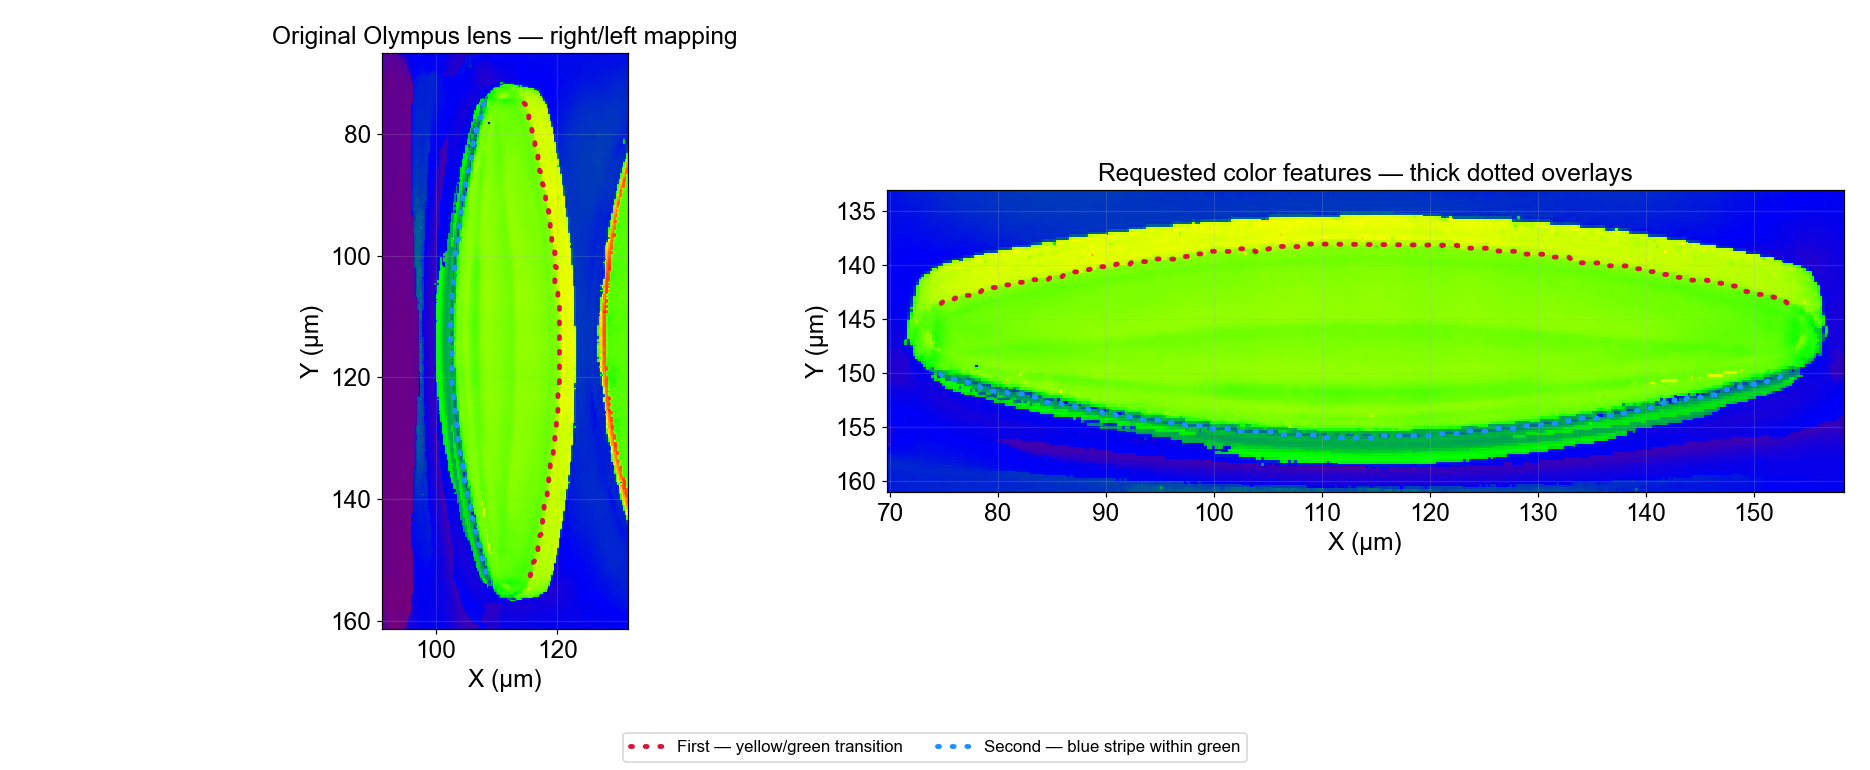

In [8]:
# Extract the CENTRAL lens: first surface on the original RIGHT, second on LEFT.
# Segment the central component to bound the two feature searches below.
# Extract integer original pixels, then transform only their coordinates.
lens_seed_xy_px = (445, 450)  # [column,row] inside the lens, in the ORIGINAL image.
lens_roi_fraction = (0.36, 0.50, 0.25, 0.64)  # xmin,xmax,ymin,ymax in original image.
lens_color_threshold = 0.25  # Boundary where (G-B)/255 crosses this level.
lens_tip_trim_um = 3.0       # Exclude rounded terminal caps from surface comparisons.

lens_color_contrast = (green - blue) / 255.0
roi_x0, roi_x1 = np.rint(np.array(lens_roi_fraction[:2]) * image_width).astype(int)
roi_y0, roi_y1 = np.rint(np.array(lens_roi_fraction[2:]) * image_height).astype(int)
lens_region = np.zeros((image_height, image_width), dtype=bool)
lens_region[roi_y0:roi_y1, roi_x0:roi_x1] = (
    lens_color_contrast[roi_y0:roi_y1, roi_x0:roi_x1] > lens_color_threshold
)
lens_labels, _ = label(lens_region)
seed_x, seed_y = lens_seed_xy_px
if not (0 <= seed_x < image_width and 0 <= seed_y < image_height):
    raise ValueError('Lens seed lies outside the image.')
lens_component_id = lens_labels[seed_y, seed_x]
if lens_component_id == 0:
    raise ValueError('Lens seed is outside the selected color region; adjust seed/threshold.')
lens_mask = lens_labels == lens_component_id
lens_rows, lens_columns = np.nonzero(lens_mask)
if (lens_columns.min() <= roi_x0 or lens_columns.max() >= roi_x1 - 1 or
        lens_rows.min() <= roi_y0 or lens_rows.max() >= roi_y1 - 1):
    raise ValueError('Selected lens region touches the ROI boundary; inspect the ROI/threshold.')
trim_px = int(np.ceil(lens_tip_trim_um / um_per_pixel))
trace_rows = np.arange(lens_rows.min() + trim_px, lens_rows.max() - trim_px + 1)
if len(trace_rows) < 20:
    raise ValueError('Too few rows remain; reduce lens_tip_trim_um.')
right_columns = []
left_columns = []
for row in trace_rows:
    columns = np.flatnonzero(lens_mask[row])
    if not columns.size:
        raise ValueError('Gap in lens segmentation; inspect the threshold and ROI.')
    left_columns.append(columns[0])
    right_columns.append(columns[-1])

# Refine the two requested color features inside the central lens component.
# First: rising red content from green into yellow on the ORIGINAL RIGHT.
# Second: the blue/cyan trough BETWEEN green bands on the ORIGINAL LEFT.
# The previous component boundary is used only to bound the searches.
edge_linewidth = 3.2
edge_linestyle = (0, (0.4, 2.6))  # Thick, separated round dots leave the image visible.
first_search_inset_px = (2, 30)   # Min/max distance inward from outer right boundary.
second_search_inset_px = (2, 18)  # Min/max distance inward from outer left boundary.
edge_smoothing_sigma_px = 1.0    # Used only for feature detection, not image display.

outer_left_columns = np.array(left_columns)
outer_right_columns = np.array(right_columns)
mid_columns = (outer_left_columns + outer_right_columns) / 2
candidate_columns = np.arange(roi_x0, roi_x1)
candidate_x = candidate_columns[None, :]
first_min_x = np.maximum(mid_columns + 1, outer_right_columns - first_search_inset_px[1])
first_max_x = outer_right_columns - first_search_inset_px[0]
second_min_x = outer_left_columns + second_search_inset_px[0]
second_max_x = np.minimum(mid_columns - 1, outer_left_columns + second_search_inset_px[1])
first_band = (candidate_x >= first_min_x[:, None]) & (candidate_x <= first_max_x[:, None])
second_band = (candidate_x >= second_min_x[:, None]) & (candidate_x <= second_max_x[:, None])

red_smoothed = gaussian_filter(red / 255.0, sigma=edge_smoothing_sigma_px)
red_gradient = np.gradient(red_smoothed, axis=1)
blue_smoothed = gaussian_filter(blue / 255.0, sigma=edge_smoothing_sigma_px)
local_red_gradient = red_gradient[trace_rows, roi_x0:roi_x1]
local_blue = blue_smoothed[trace_rows, roi_x0:roi_x1]
local_green = green[trace_rows, roi_x0:roi_x1] / 255.0
local_raw_blue = blue[trace_rows, roi_x0:roi_x1] / 255.0
# Reject the outer blue background when looking for the yellow/green transition.
first_band &= (local_green > 0.65) & (local_raw_blue < 0.20)
# A blue/cyan stripe still has green present; exclude the exterior blue field.
second_band &= local_green > 0.20


def trace_color_feature(response, allowed):
    """Continuous path through integer ORIGINAL pixels, one point per image row."""
    if not np.all(allowed.any(axis=1)):
        raise ValueError('A color-search band is empty; adjust the search insets or tip trim.')
    score = np.maximum(response, 0).copy()
    score /= max(float(np.percentile(score[allowed], 95)), 1e-9)
    score[~allowed] = -np.inf
    states = np.arange(len(candidate_columns))
    shifts = np.arange(-3, 4)
    previous_states = np.empty(score.shape, dtype=np.int32)
    cost = -score[0]
    for row in range(1, len(trace_rows)):
        choices = np.full((len(shifts), len(states)), np.inf)
        for k, shift in enumerate(shifts):
            previous = states + shift
            valid = (previous >= 0) & (previous < len(states))
            choices[k, valid] = cost[previous[valid]] + 0.08 * shift**2
        best = np.argmin(choices, axis=0)
        previous_states[row] = states + shifts[best]
        cost = choices[best, states] - score[row]
    if not np.isfinite(cost).any():
        raise ValueError('No continuous color-feature path; adjust search bands.')
    path = np.empty(len(trace_rows), dtype=int)
    path[-1] = np.argmin(cost)
    for row in range(len(trace_rows) - 1, 0, -1):
        path[row - 1] = previous_states[row, path[row]]
    return np.column_stack([candidate_columns[path], trace_rows])

first_pixels = trace_color_feature(local_red_gradient, first_band)
second_pixels = trace_color_feature(local_blue, second_band)

def olympus_edge_coordinates(pixels):
    original_xy_um = (pixels + 0.5) * um_per_pixel
    rotated_xy_um = measured_rotation_transform_um.transform(original_xy_um)
    order = np.argsort(rotated_xy_um[:, 0])
    return pixels[order], original_xy_um[order], rotated_xy_um[order]

(measured_first_edge_pixels, measured_first_edge_original_xy_um,
 measured_first_edge_xy_um) = olympus_edge_coordinates(first_pixels)
(measured_second_edge_pixels, measured_second_edge_original_xy_um,
 measured_second_edge_xy_um) = olympus_edge_coordinates(second_pixels)
# Compatibility with the original notebook: after rotation first is above second.
measured_top_edge_pixels = measured_first_edge_pixels
measured_bottom_edge_pixels = measured_second_edge_pixels
measured_top_edge_xy_um = measured_first_edge_xy_um
measured_bottom_edge_xy_um = measured_second_edge_xy_um

fig_lens_edges, axes_lens_edges = plt.subplots(1, 2, figsize=(17, 7))
original_axis, rotated_axis = axes_lens_edges
original_axis.imshow(measured_rgb, extent=image_extent_um, origin='upper',
                     interpolation='none', resample=False)
original_axis.plot(*measured_first_edge_original_xy_um.T, color='crimson', linewidth=edge_linewidth, linestyle=edge_linestyle, dash_capstyle='round',
                   label='First — yellow/green transition')
original_axis.plot(*measured_second_edge_original_xy_um.T, color='dodgerblue', linewidth=edge_linewidth, linestyle=edge_linestyle, dash_capstyle='round',
                   label='Second — blue stripe within green')
original_axis.set(title='Original Olympus lens — right/left mapping')
# Show all of the selected central component plus a small margin.
original_axis.set(
    xlim=((lens_columns.min() - 35) * um_per_pixel, (lens_columns.max() + 35) * um_per_pixel),
    ylim=((lens_rows.max() + 20) * um_per_pixel, (lens_rows.min() - 20) * um_per_pixel),
)
image_artist = rotated_axis.imshow(
    measured_rgb, extent=image_extent_um, origin='upper', interpolation='none', resample=False,
    transform=measured_rotation_transform_um + rotated_axis.transData, clip_on=True,
)
image_artist.set_clip_path(rotated_axis.patch)
rotated_axis.plot(*measured_first_edge_xy_um.T, color='crimson', linewidth=edge_linewidth, linestyle=edge_linestyle, dash_capstyle='round',
                  label='First — yellow/green transition')
rotated_axis.plot(*measured_second_edge_xy_um.T, color='dodgerblue', linewidth=edge_linewidth, linestyle=edge_linestyle, dash_capstyle='round',
                  label='Second — blue stripe within green')
all_rotated_points = np.vstack([measured_first_edge_xy_um, measured_second_edge_xy_um])
rotated_axis.set(
    title='Requested color features — thick dotted overlays',
    xlim=(all_rotated_points[:, 0].min() - 5, all_rotated_points[:, 0].max() + 5),
    ylim=(all_rotated_points[:, 1].max() + 5, all_rotated_points[:, 1].min() - 5),
)
for axis in axes_lens_edges:
    axis.set(xlabel='X (µm)', ylabel='Y (µm)')
    axis.set_aspect('equal')
    axis.grid(alpha=0.2)
handles, legend_labels = original_axis.get_legend_handles_labels()
fig_lens_edges.legend(handles, legend_labels, loc='lower center', ncol=2, fontsize=11)
fig_lens_edges.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()
print(f'First (original right): {len(measured_first_edge_xy_um)} points in measured_first_edge_xy_um.')
print(f'Second (original left): {len(measured_second_edge_xy_um)} points in measured_second_edge_xy_um.')
print('Arrays contain rotated [X,Y] in µm; *_original_xy_um and *_pixels retain original locations.')
print(f'Component threshold (search ROI only): {lens_color_threshold}; terminal-cap trim: {lens_tip_trim_um:g} µm per end.')
print('No image resampling, theory fitting, or scale adjustment during edge extraction.')

print('First traces the yellow/green transition; second traces the blue stripe between green bands.')


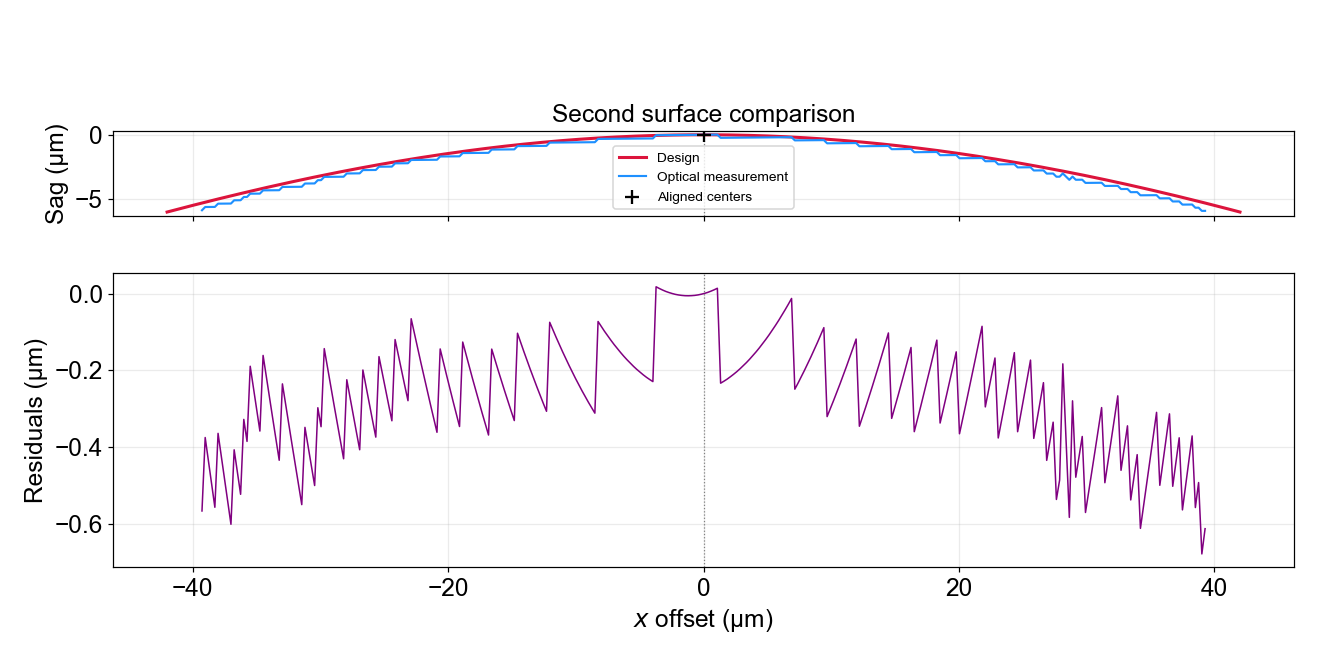

In [9]:
# Olympus second surface = original LEFT edge (bottom after rotation).
# Compare the TIFF bottom (blue) and STL top curves using center_profile defined above.
# Compare the opposing convex surfaces with the same crown orientation:
# use TIFF downward-positive Y and STL upward-positive Z as profile ordinates.
# Thus both centers are maxima. Relative to the TIFF display this reverses its
# vertical plotting direction; original numerical coordinates are unchanged.
# Align at the midpoint of each sampled X span; no scale or curvature fitting.

stl_top_centered_um, stl_profile_center_um = center_profile(top_edge_xz_um)
tiff_bottom_centered_um, tiff_profile_center_um = center_profile(measured_second_edge_xy_um)

# Evaluate the STL only within the shared X span to show TIFF − STL differences.
# This interpolates curve coordinates for comparison; no image pixels are resampled.
shared_x_min = max(stl_top_centered_um[0, 0], tiff_bottom_centered_um[0, 0])
shared_x_max = min(stl_top_centered_um[-1, 0], tiff_bottom_centered_um[-1, 0])
if shared_x_min >= shared_x_max:
    raise ValueError('The centered profiles have no overlapping X range.')
in_shared_span = ((tiff_bottom_centered_um[:, 0] >= shared_x_min) &
                  (tiff_bottom_centered_um[:, 0] <= shared_x_max))
comparison_x_um = tiff_bottom_centered_um[in_shared_span, 0]
stl_height_at_tiff_um = np.interp(
    comparison_x_um, stl_top_centered_um[:, 0], stl_top_centered_um[:, 1]
)
profile_difference_um = (
    tiff_bottom_centered_um[in_shared_span, 1] - stl_height_at_tiff_um
)

fig_profile_comparison, axes_profile_comparison = plt.subplots(
    2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [1, 1]},
)
overlay_axis, difference_axis = axes_profile_comparison
overlay_axis.plot(*stl_top_centered_um.T, color='crimson', linewidth=2,
                  label='Design')
overlay_axis.plot(*tiff_bottom_centered_um.T, color='dodgerblue', linewidth=1.4,
                  label='Optical measurement')
overlay_axis.scatter([0], [0], color='black', marker='+', s=80, zorder=5,
                     label='Aligned centers')
overlay_axis.set(ylabel='Sag (µm)',
                 title='Second surface comparison')
overlay_axis.set_aspect('equal', adjustable='box')
overlay_axis.legend(loc='lower center', fontsize=9)
difference_axis.plot(comparison_x_um, profile_difference_um, color='purple', linewidth=1)
difference_axis.set(xlabel='$x$ offset (µm)',
                    ylabel='Residuals (µm)')
for axis in axes_profile_comparison:
    axis.axvline(0, color='gray', linestyle=':', linewidth=0.8)
    axis.grid(alpha=0.25)
fig_profile_comparison.tight_layout()
plt.show()


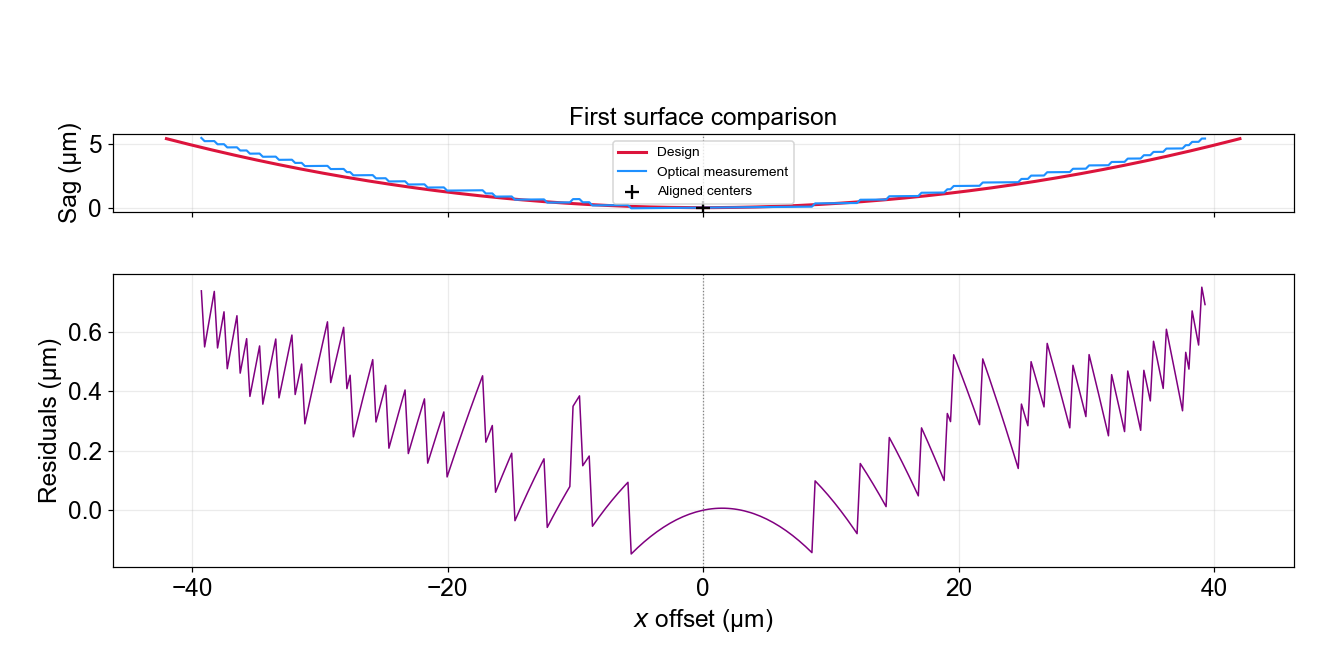

In [10]:
# Olympus first surface = original RIGHT edge (top after rotation).
# First surface: TIFF top edge versus STL bottom (lower-Z) edge.
# Use TIFF Y and STL Z directly; both centered profiles have a minimum at the center.
# Align at the midpoint of each sampled X span; no scaling or curvature fitting.

stl_bottom_centered_um, stl_profile_center_um = center_profile(bottom_edge_xz_um)
tiff_top_centered_um, tiff_profile_center_um = center_profile(measured_first_edge_xy_um)

# Compare only within the shared X span.
# Interpolation applies to curve coordinates, not image pixels.
shared_x_min = max(stl_bottom_centered_um[0, 0], tiff_top_centered_um[0, 0])
shared_x_max = min(stl_bottom_centered_um[-1, 0], tiff_top_centered_um[-1, 0])
if shared_x_min >= shared_x_max:
    raise ValueError('The centered profiles have no overlapping X range.')

in_shared_span = (
    (tiff_top_centered_um[:, 0] >= shared_x_min)
    & (tiff_top_centered_um[:, 0] <= shared_x_max)
)
comparison_x_um = tiff_top_centered_um[in_shared_span, 0]
stl_height_at_tiff_um = np.interp(
    comparison_x_um,
    stl_bottom_centered_um[:, 0],
    stl_bottom_centered_um[:, 1],
)
profile_difference_um = (
    tiff_top_centered_um[in_shared_span, 1] - stl_height_at_tiff_um
)

fig_profile_comparison, axes_profile_comparison = plt.subplots(
    2, 1, figsize=(12, 6), sharex=True,
    gridspec_kw={'height_ratios': [1, 1]},
)
overlay_axis, difference_axis = axes_profile_comparison

overlay_axis.plot(
    *stl_bottom_centered_um.T, color='crimson', linewidth=2,
    label='Design',
)
overlay_axis.plot(
    *tiff_top_centered_um.T, color='dodgerblue', linewidth=1.4,
    label='Optical measurement',
)
overlay_axis.scatter(
    [0], [0], color='black', marker='+', s=80, zorder=5,
    label='Aligned centers',
)
overlay_axis.set(ylabel='Sag (µm)', title='First surface comparison')
overlay_axis.set_aspect('equal', adjustable='box')
overlay_axis.legend(loc='upper center', fontsize=9)

difference_axis.plot(
    comparison_x_um, profile_difference_um, color='purple', linewidth=1,
)
difference_axis.set(
    xlabel='$x$ offset (µm)',
    ylabel='Residuals (µm)',
)

for axis in axes_profile_comparison:
    axis.axvline(0, color='gray', linestyle=':', linewidth=0.8)
    axis.grid(alpha=0.25)

fig_profile_comparison.tight_layout()
plt.show()

First surface / TIFF right (original): RMS 0.3292 µm; max |difference| 0.7518 µm.
Second surface / TIFF left (original): RMS 0.2974 µm; max |difference| 0.6790 µm.
Assumptions: design units = µm; optical y = 0; offscreen higher X coefficients = 0.
Center translations only; supplied parameters unchanged; no image resampling.


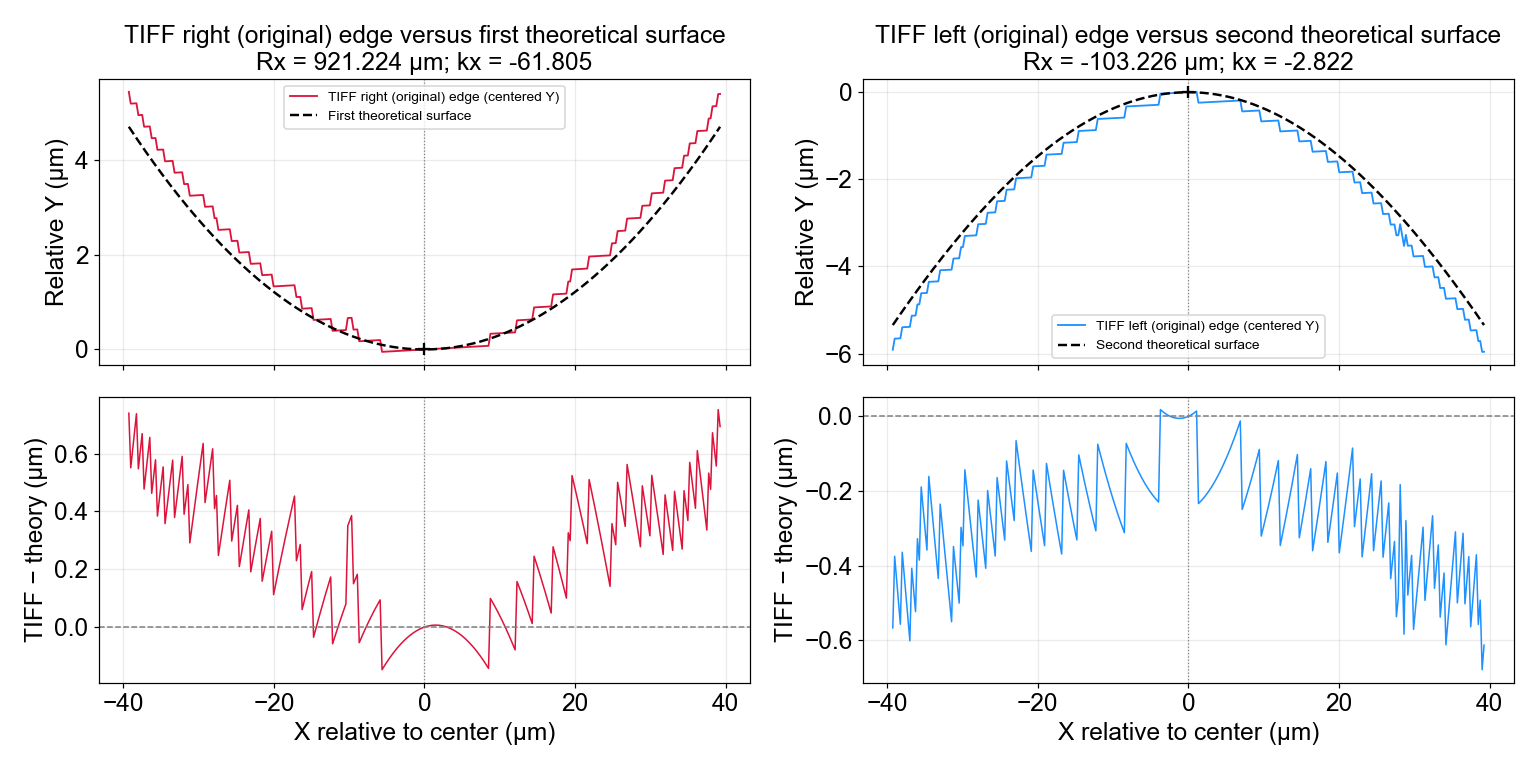

In [11]:
# TIFF comparison using the first/second theoretical parameters defined above.
fig_asphere, axes_asphere = plt.subplots(2, 2, figsize=(14, 7), sharex='col')
asphere_comparison_results = {}
for column, (surface_name, edge_name, measured_edge, color) in enumerate([
    ('first', 'right (original)', measured_first_edge_xy_um, 'crimson'),
    ('second', 'left (original)', measured_second_edge_xy_um, 'dodgerblue'),
]):
    # Same center alignment as earlier comparisons: midpoint of sampled X span.
    measured_centered, measured_center = center_profile(measured_edge)
    parameters = asphere_parameters[surface_name]
    model_arguments = (parameters['radius_um'], parameters['conic_constant'],
                       parameters['x_coefficients'])
    theory_x_um = np.linspace(measured_centered[0, 0], measured_centered[-1, 0], 1501)
    theory_sag_um = biconic_x_sag_um(theory_x_um, *model_arguments)
    theory_at_points_um = biconic_x_sag_um(measured_centered[:, 0], *model_arguments)
    difference_um = measured_centered[:, 1] - theory_at_points_um
    valid = np.isfinite(difference_um)
    profile_axis, residual_axis = axes_asphere[:, column]
    profile_axis.plot(*measured_centered.T, color=color, linewidth=1.2,
                      label=f'TIFF {edge_name} edge (centered Y)')
    profile_axis.plot(theory_x_um, theory_sag_um, 'k--', linewidth=1.6,
                      label=f'{surface_name.capitalize()} theoretical surface')
    profile_axis.scatter([0], [0], color='black', marker='+', s=60, zorder=5)
    profile_axis.set(title=f'TIFF {edge_name} edge versus {surface_name} theoretical surface\n'
                     f'Rx = {parameters["radius_um"]:g} µm; kx = {parameters["conic_constant"]:g}',
                     ylabel='Relative Y (µm)')
    profile_axis.legend(loc='best', fontsize=9)
    residual_axis.plot(measured_centered[:, 0], difference_um, color=color, linewidth=1)
    residual_axis.axhline(0, color='gray', linestyle='--', linewidth=1)
    residual_axis.set(xlabel='X relative to center (µm)', ylabel='TIFF − theory (µm)')
    asphere_comparison_results[surface_name] = {
        'parameters': parameters,
        'measured_center_xy_um': measured_center,
        'measured_centered_xy_um': measured_centered,
        'theory_at_measured_x_um': theory_at_points_um,
        'difference_um': difference_um,
        'valid': valid,
    }
    if valid.any():
        rms_um = np.sqrt(np.mean(difference_um[valid]**2))
        max_abs_um = np.max(np.abs(difference_um[valid]))
        print(f'{surface_name.capitalize()} surface / TIFF {edge_name}: RMS {rms_um:.4f} µm; max |difference| {max_abs_um:.4f} µm.')
    if not valid.all():
        print(f'{edge_name.capitalize()}: {np.sum(~valid)} points outside the real conic domain; excluded.')
    for axis in (profile_axis, residual_axis):
        axis.axvline(0, color='gray', linestyle=':', linewidth=0.8)
        axis.grid(alpha=0.25)
fig_asphere.tight_layout()
plt.show()
print('Assumptions: design units = µm; optical y = 0; offscreen higher X coefficients = 0.')
print('Center translations only; supplied parameters unchanged; no image resampling.')
